# Crystal-field tomography, 2D toy
Fine multislice of a twinned particle (no objective aperture), binned below lattice resolution, compared with the coarse crystal-field forward model and a first inversion.

In [1]:
import sys
from pathlib import Path

import numpy as np
import torch

HERE = Path.cwd()
sys.path.insert(0, str(HERE))

from quantem.core.visualization.visualization import show_2d

from coarse2d import Coarse2D
import footprints
import invert2d
import signatures
import sim2d

torch.set_num_threads(4)

## Simulate

In [2]:
sim2d.main("few")
d = np.load("runs/sim_few.npz")
cfg = __import__("json").loads(str(d["cfg"]))
refl = __import__("json").loads(str(d["refl"]))
angles = d["angles"]
data = d["I_coarse"]

few: 3498 atoms, 3 grains, 63 Friedel pairs, multislice 1.6 s -> /Users/cophus/Library/CloudStorage/Dropbox/python/quantem/tomography/crystal_field_2d/runs/sim_few.npz


## Coarse forward model with true parameters

In [3]:
model = Coarse2D(
    cfg,
    angles,
    s_cut=0.04,
)
g = torch.as_tensor([e["g"] for e in refl], dtype=torch.float64)
rho = torch.as_tensor([complex(*e["rho"]) for e in refl], dtype=torch.complex128)
grain = torch.as_tensor([e["grain"] for e in refl])
pred_true = model.forward(
    torch.as_tensor(d["vbar"], dtype=torch.float64),
    torch.as_tensor(d["occ"], dtype=torch.float64),
    g,
    rho,
    grain,
).numpy()
pred_mean = model.forward(
    torch.as_tensor(d["vbar"], dtype=torch.float64),
    None,
).numpy()
crop = slice(model.n_out // 2 - 64, model.n_out // 2 + 64)

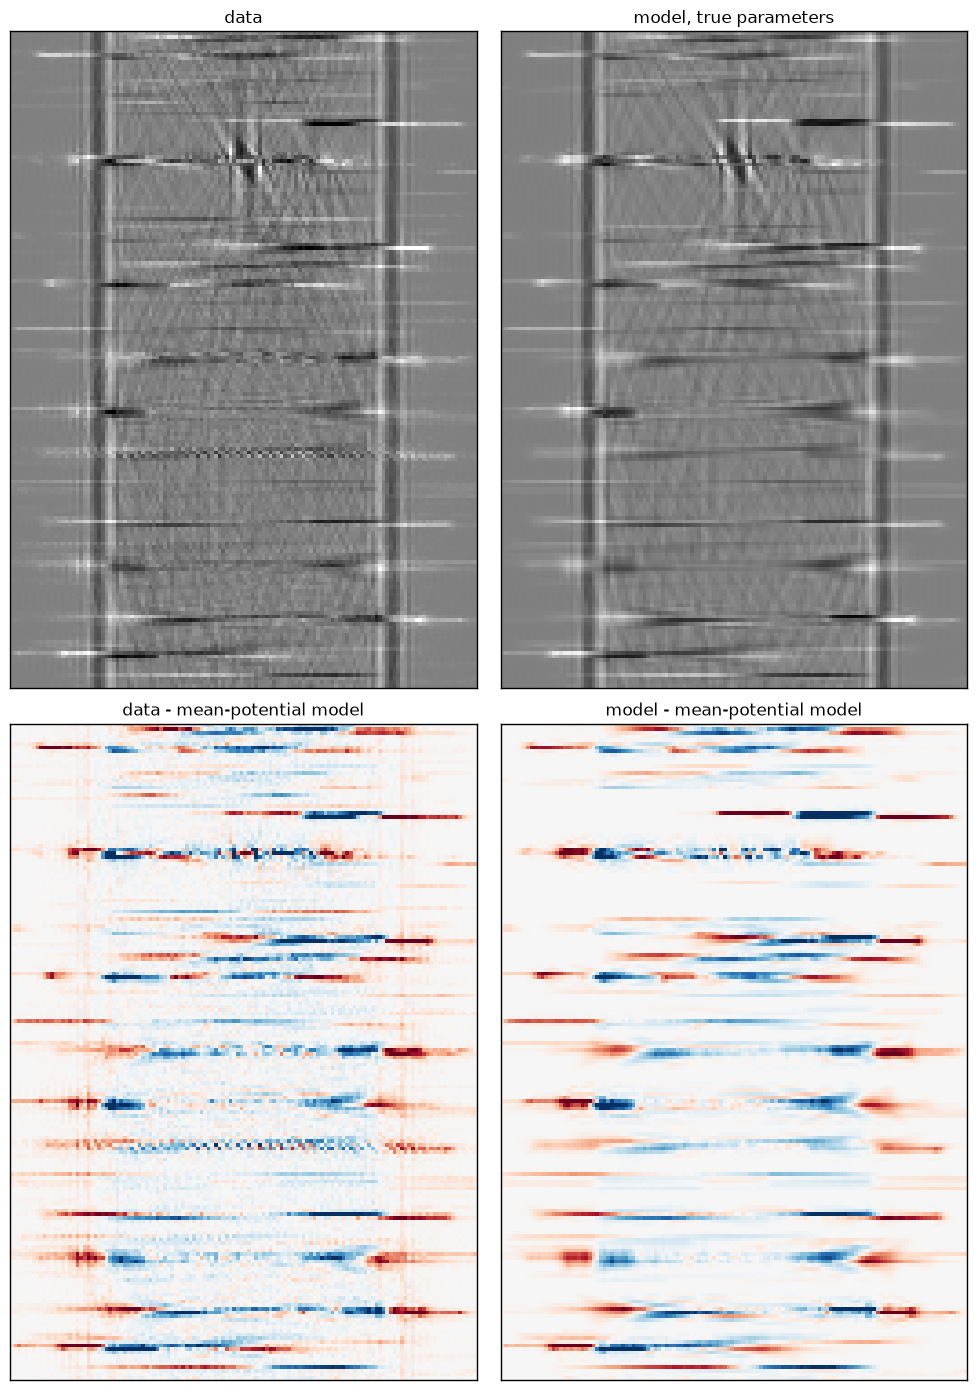

In [4]:
norm_int = {"interval_type": "manual", "vmin": 0.2, "vmax": 1.8}
norm_diff = {"interval_type": "centered", "half_range": 0.5}
show_2d(
    [
        [data[:, crop], pred_true[:, crop]],
        [data[:, crop] - pred_mean[:, crop], pred_true[:, crop] - pred_mean[:, crop]],
    ],
    norm=[[norm_int, norm_int], [norm_diff, norm_diff]],
    cmap=[["gray", "gray"], ["RdBu_r", "RdBu_r"]],
    title=[["data", "model, true parameters"], ["data - mean-potential model", "model - mean-potential model"]],
    axsize=(5, 7),
);

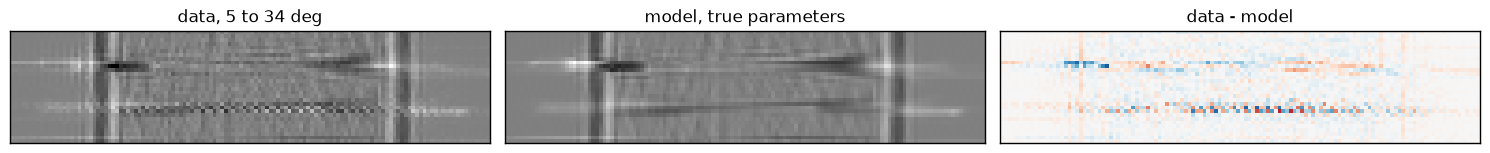

In [5]:
tilts = slice(95, 125)
show_2d(
    [data[tilts, crop], pred_true[tilts, crop], data[tilts, crop] - pred_true[tilts, crop]],
    norm=[norm_int, norm_int, norm_diff],
    cmap=["gray", "gray", "RdBu_r"],
    title=["data, 5 to 34 deg", "model, true parameters", "data - model"],
    axsize=(5, 3),
);

## Inversion
Footprints per tilt, grain masks from flash signatures, then the sparse set model.

In [6]:
footprints.run(
    kind="few",
    S=10,
    u0=[-1.15, -0.95, -0.75, -0.55, -0.35, 0.35, 0.55, 0.75, 0.95, 1.15],
    warm=600,
    iters=2000,
    tag="_s10",
)

it    0 nmse 1.0071  footprint mass 462.6  slots >5% of max 1800  0s


it  250 nmse 0.6463  footprint mass 462.6  slots >5% of max 1800  3s


it  500 nmse 0.6496  footprint mass 462.6  slots >5% of max 1800  5s


it  750 nmse 0.0192  footprint mass 1999.6  slots >5% of max 822  8s


it 1000 nmse 0.0829  footprint mass 1807.3  slots >5% of max 620  11s


it 1250 nmse 0.0219  footprint mass 1707.5  slots >5% of max 554  13s


it 1500 nmse 0.0586  footprint mass 1643.8  slots >5% of max 485  16s


it 1750 nmse 0.0388  footprint mass 1603.7  slots >5% of max 436  19s


it 1999 nmse 0.0923  footprint mass 1584.1  slots >5% of max 419  22s


final nmse (all tilts) 0.0665


In [7]:
import subprocess
subprocess.run([sys.executable, "signatures.py", "few", "3"], check=True)
invert2d.run(
    kind="few",
    K=3,
    iters=1500,
    log_every=150,
    lam_l1=1e-3,
    warm=0,
    init_from_sig=True,
    tag="_t3",
)
inv = np.load("runs/inv_few_t3.npz")
pred_inv = inv["pred"]

confusion (rows GT grain, cols cluster), particle voxels only:
 [[ 522 1935   55]
 [ 581  104  666]
 [ 137    0 1018]]
it    0  nmse 0.6359  cells 0/34 (active slots 0)  IoU 0.58 0.23 0.36  0s


/Users/cophus/Library/CloudStorage/Dropbox/python/quantem/tomography/crystal_field_2d/invert2d.py:160: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /Users/runner/work/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:821.)
  print(f"it {it:4d}  nmse {float(mse):.4f}  cells {f}/{s} (active slots {ns})  "


it  150  nmse 0.1110  cells 10/34 (active slots 90)  IoU 0.46 0.20 0.29  10s


it  300  nmse 0.1057  cells 10/34 (active slots 92)  IoU 0.41 0.18 0.25  20s


it  450  nmse 0.0773  cells 10/34 (active slots 94)  IoU 0.39 0.17 0.24  29s


it  600  nmse 0.0941  cells 10/34 (active slots 98)  IoU 0.39 0.17 0.24  39s


... (2 outputs left out)

it 1050  nmse 0.0884  cells 10/34 (active slots 97)  IoU 0.37 0.16 0.23  72s


it 1200  nmse 0.0837  cells 11/34 (active slots 96)  IoU 0.37 0.16 0.22  82s


it 1350  nmse 0.1130  cells 12/34 (active slots 94)  IoU 0.37 0.16 0.22  92s


it 1499  nmse 0.1300  cells 13/34 (active slots 94)  IoU 0.36 0.16 0.22  101s


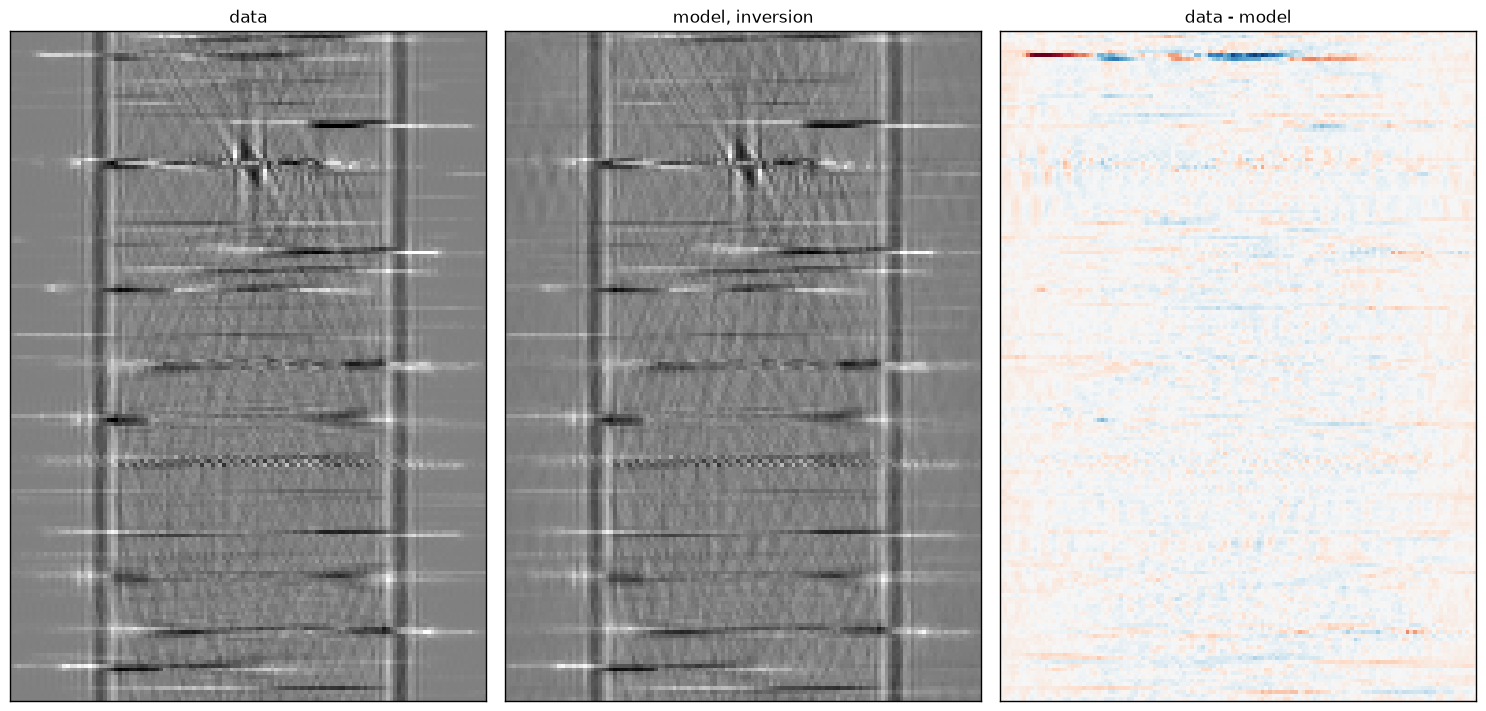

In [8]:
show_2d(
    [data[:, crop], pred_inv[:, crop], data[:, crop] - pred_inv[:, crop]],
    norm=[norm_int, norm_int, norm_diff],
    cmap=["gray", "gray", "RdBu_r"],
    title=["data", "model, inversion", "data - model"],
    axsize=(5, 7),
);

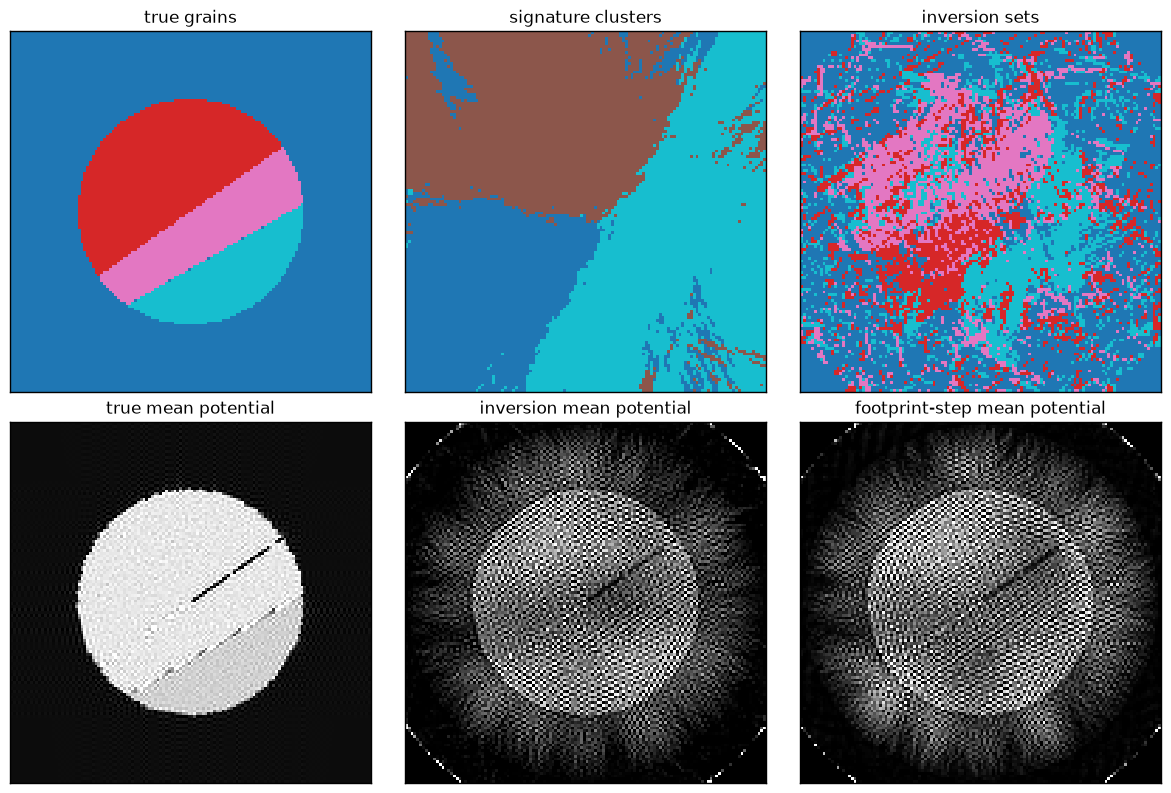

In [9]:
occ = d["occ"]
labels_true = np.where(occ.max(0) > 0.5, occ.argmax(0), -1)
W = inv["W"]
labels_inv = np.where(W.sum(0) > 0.5, W.argmax(0), -1)
show_2d(
    [
        [np.flipud(labels_true.T), np.flipud(np.load("runs/sig_few.npz")["lab"].T), np.flipud(labels_inv.T)],
        [np.flipud(d["vbar"].T), np.flipud(inv["vbar"].T), np.flipud(np.load("runs/fp_few_s10.npz")["vbar"].T)],
    ],
    cmap=[["tab10", "tab10", "tab10"], ["gray", "gray", "gray"]],
    title=[["true grains", "signature clusters", "inversion sets"], ["true mean potential", "inversion mean potential", "footprint-step mean potential"]],
);